# Diabetic Retinopathy – v2 (professor's suggestions applied)

All modifications are marked in the code with **`# [CHANGED]`** (existing code modified) or
**`# [ADDED]`** (new code), and each modified section is preceded by a markdown cell titled **CHANGE n**.

| # | Change | Why |
|---|--------|-----|
| 1 | **Model**: EfficientNet-B0 → **EfficientNetV2-S** | Stronger backbone, better accuracy at high resolution |
| 2 | **Train/validation split by patient** (`StratifiedGroupKFold`) | Left and right eye of the same patient are strongly correlated → both must be in train OR in validation, otherwise the validation score leaks |
| 3 | **Loss**: CrossEntropy → **MSE** (regression, 1 output) | Levels 0–4 are ordered; MSE penalises big mistakes more (closer to the quadratic weighted kappa metric) |
| 4 | **Predicted distribution = train distribution** | Continuous scores are ranked and cut so that the % of each level in the predictions equals the % in train |
| 5 | **Added**: quadratic weighted kappa on validation, best model saved on kappa, mixed precision (AMP) | Competition metric / speed for the bigger model on the T4 |
| 6 | **Fix (EDA)**: image size and corrupted image checks used `row.image` instead of `img_name` | They were checking the same image 35 126 times |

**Note:** this notebook is only used to train and obtain the best model (`best_model.pth`).
The test predictions are made with `image_prediction.py` on the already preprocessed test images
(crop + resize 512 + Ben Graham); that script was updated accordingly (same model, 1 output, same distribution matching).
To run it, download from the Kaggle output **`best_model.pth`** and **`train_level_props.json`**.

# Libraries

In [ ]:
import pandas as pd
import os
from glob import glob
import matplotlib.pyplot as plt
import cv2
import numpy as np
from PIL import Image
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset
# [CHANGED] EfficientNet-B0 -> EfficientNetV2-S (see CHANGE 1)
from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
# [CHANGED] train_test_split -> StratifiedGroupKFold to split by patient (see CHANGE 2)
from sklearn.model_selection import StratifiedGroupKFold
# [ADDED] Quadratic weighted kappa = official metric of the Kaggle competition
from sklearn.metrics import cohen_kappa_score
# [ADDED] To save the train level distribution next to the model (read by image_prediction.py)
import json

In [ ]:
# To check the device used

print(torch.cuda.get_device_name(0))
print(torch.cuda.get_device_capability(0))


Tesla T4
(7, 5)


# Load raw data

In [3]:
file_lbl="/kaggle/input/diabetic-retinopathy-detection/trainLabels.csv.zip"
df_train=pd.read_csv(file_lbl,sep=',')
df_train

,image,level
0,10_left,0
1,10_right,0
2,13_left,0
3,13_right,0
4,15_left,1
...,...,...
35121,44347_right,0
35122,44348_left,0
35123,44348_right,0
35124,44349_left,0


In [4]:
#Missing data on the train dataset?
print(df_train.isnull().sum())

image    0
level    0
dtype: int64


In [5]:
#Duplicates?
print(df_train.duplicated().sum())

#Unique image names?
print(df_train["image"].nunique())

0
35126


In [6]:
#Number of entries per level
print(df_train["level"].value_counts())
#Strong class imbalance, most of the data is level 0 so the algo will learn to predict mostly 0

level
0    25810
2     5292
1     2443
3      873
4      708
Name: count, dtype: int64


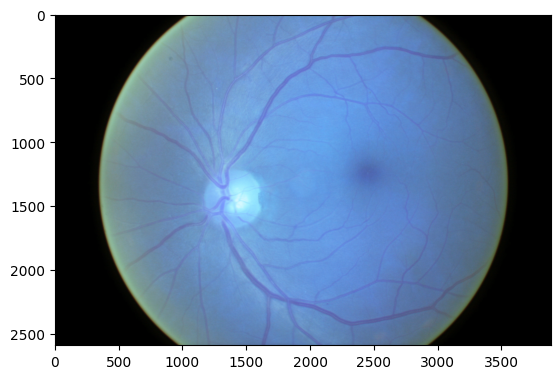

In [7]:
paths_train= glob('/kaggle/input/diabetic-retinopathy-train-unzipped/train/*.jpeg')
image=cv2.imread(paths_train[0])
plt.imshow(image)

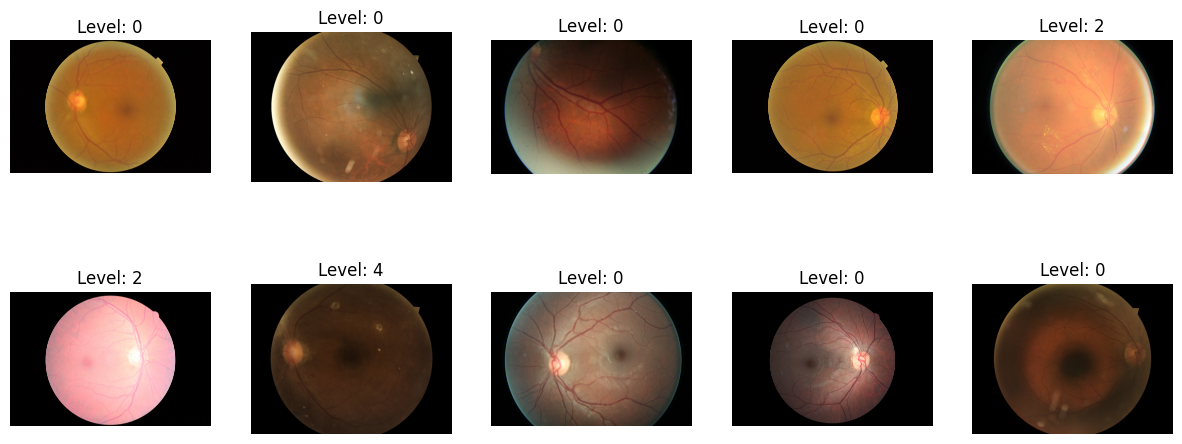

In [8]:
#plot random images from train
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

samples = df_train.sample(10)

for ax, (_, row) in zip(axes.flat, samples.iterrows()):

    img = Image.open(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{row.image}.jpeg")

    ax.imshow(img)
    ax.set_title(f"Level: {row.level}")
    ax.axis("off")

plt.show()


Are some blurry? Some yes
Are some too dark? YES
Do some have large black borders? All of them
Are they all centered? YES
Are inverted? Some of them
Same zoom? NO

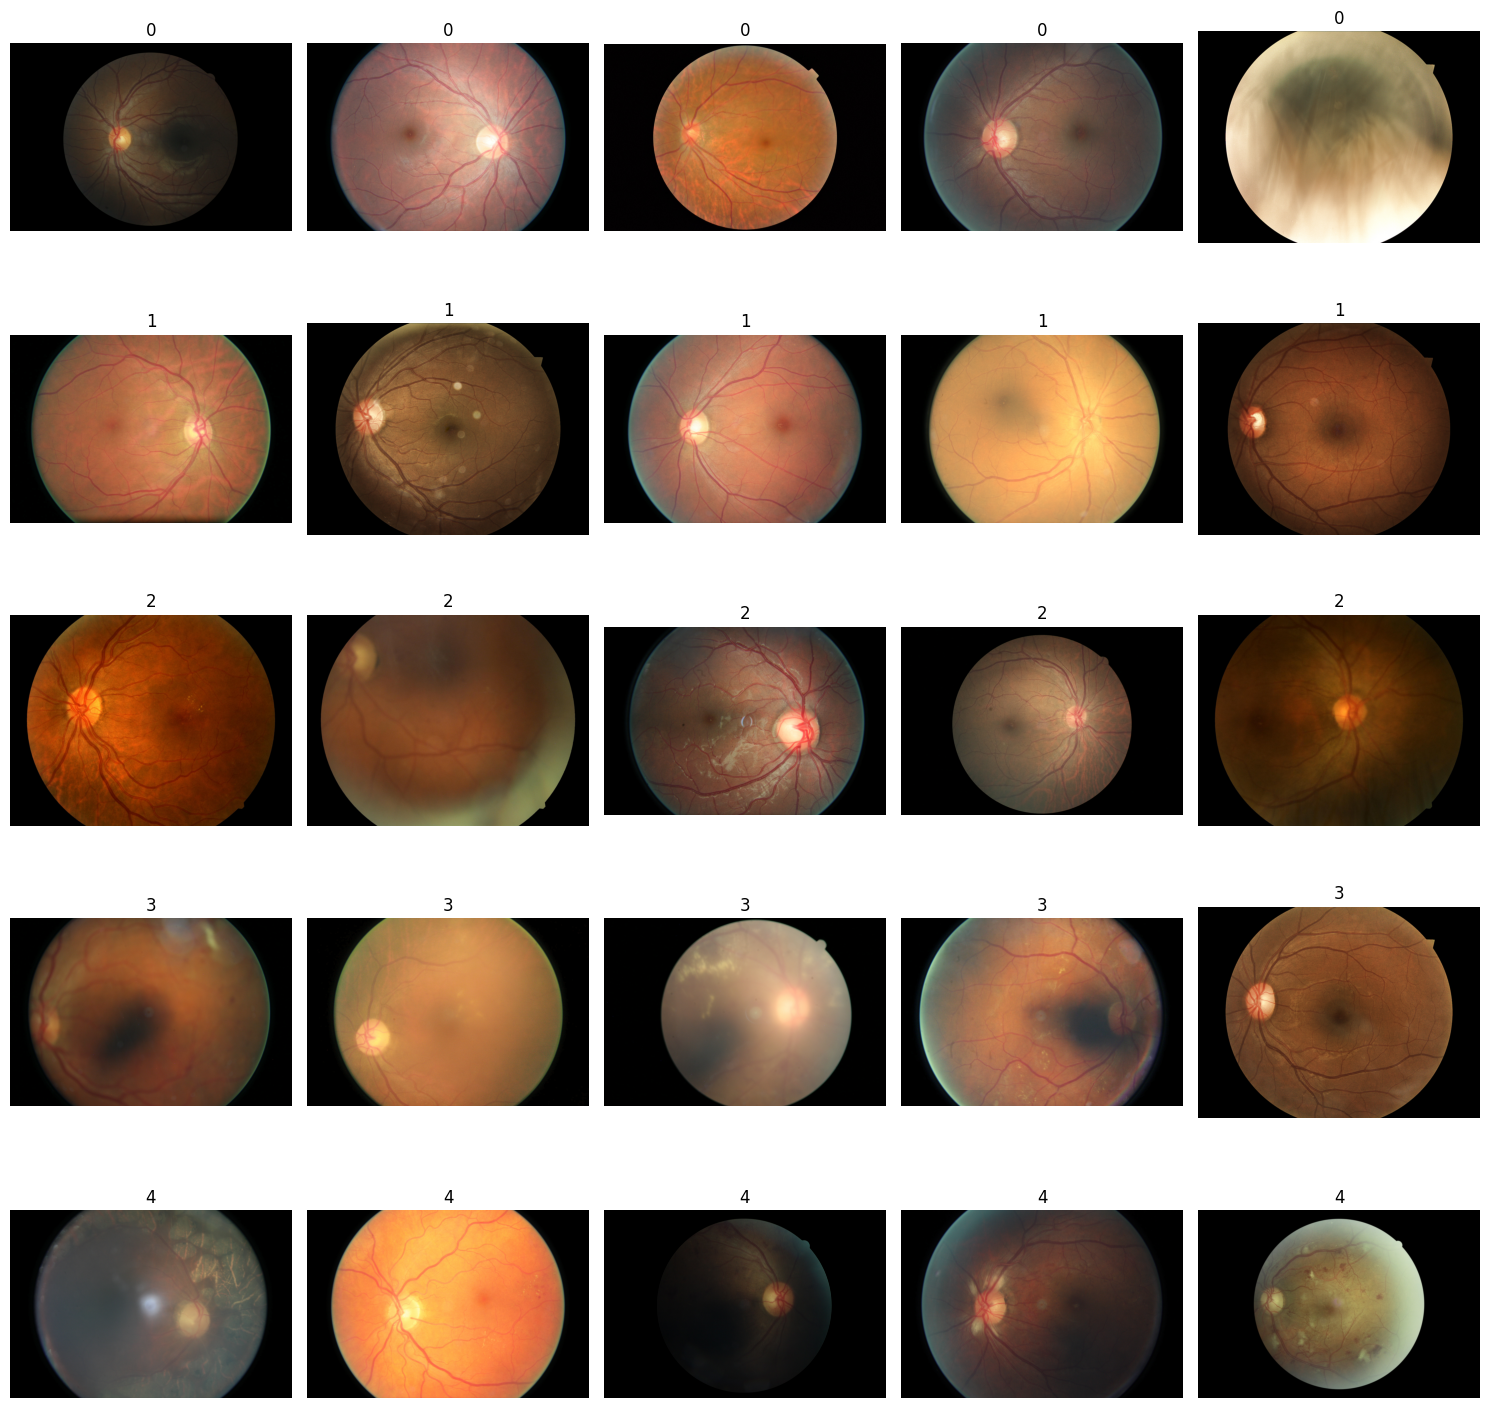

In [9]:
#Example images per class
fig, axes = plt.subplots(5,5, figsize=(15,15))

for level in range(5):

    samples = df_train[df_train.level == level].sample(5)

    for ax, (_, row) in zip(axes[level], samples.iterrows()):

        img = Image.open(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{row.image}.jpeg")

        ax.imshow(img)
        ax.set_title(level)
        ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
#Image sizes
sizes = []

#for first 500 images
#for img_name in df_train.image[:500]:

#For all images
for img_name in df_train.image[:]:
    # [CHANGED] {row.image} -> {img_name}: before, the loop opened always the same image
    # (the last `row` of the previous plotting cell), so all the sizes were identical
    img = Image.open(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{img_name}.jpeg")
    sizes.append(img.size)

print(sizes[:10])
print("-----------------")

size_df = pd.DataFrame(sizes, columns=["width","height"])
print(size_df.describe())

# [CHANGED] The previous conclusion ("all images have the same size") came from the bug above:
# re-run this cell to see the real distribution of widths/heights.

In [ ]:
# [CHANGED] (output cleared: it was based on the buggy size cell above, re-run it)
size_df.hist(figsize=(10,4))
plt.show()

In [ ]:
bad_images = []

for img_name in df_train.image:

    try:
        # [CHANGED] {row.image} -> {img_name} (same bug as the image size cell)
        img = Image.open(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{img_name}.jpeg")
        # [ADDED] Image.open is lazy (only reads the header): verify() checks that the file is not corrupted
        img.verify()

    except Exception:
        bad_images.append(img_name)

print(bad_images)

# [CHANGED] Re-run to confirm: the previous result was obtained by opening always the same image

In [13]:
#Check brightness of the images. First we convert to gray scale and then we get the average brightness of the image (sample = first 500 images)

brightness = []

for img_name in df_train.image[:500]:
    
    img = cv2.imread(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{img_name}.jpeg")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    brightness.append(gray.mean())
    
print(brightness[:10])    

[np.float64(56.90911894088188), np.float64(24.79443948906149), np.float64(57.706481124256975), np.float64(58.32477304336229), np.float64(60.93454818006748), np.float64(63.62240173945999), np.float64(97.60623112663848), np.float64(87.658328252807), np.float64(43.37068323950236), np.float64(52.02923872678834)]


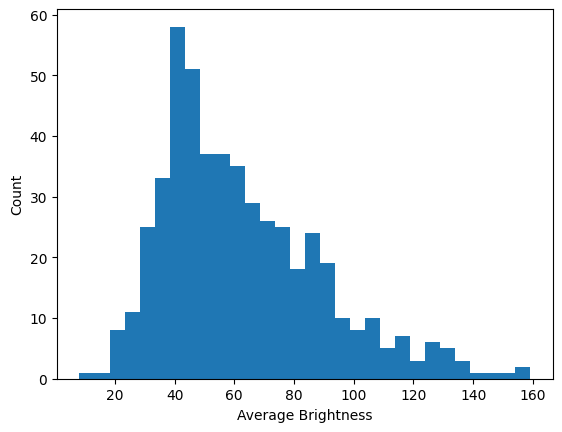

In [14]:
#plot brightness
plt.hist(brightness, bins=30)
plt.xlabel("Average Brightness")
plt.ylabel("Count")
plt.show()

In [15]:
#check image blur with laplacian
def blur_score(img):

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var()


blur_scores = []

for img_name in df_train.image[:500]:

    img = cv2.imread(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{img_name}.jpeg")

    if img is None:
        continue

    score = blur_score(img)

    blur_scores.append(score)

In [16]:
print(blur_scores[:50])    

[np.float64(11.920238129400062), np.float64(9.06666424875863), np.float64(14.18684661872508), np.float64(12.475991529928912), np.float64(7.3573514366684085), np.float64(7.192324497270499), np.float64(9.168894745423318), np.float64(9.831586679798153), np.float64(14.188539721776701), np.float64(15.937803640831815), np.float64(12.96814589366455), np.float64(17.769031234911992), np.float64(7.6575274402491225), np.float64(7.901143955940471), np.float64(12.236006822220522), np.float64(12.520478817531359), np.float64(94.27785824723043), np.float64(51.99864903531321), np.float64(21.093315575305937), np.float64(18.981660887567756), np.float64(6.123721133798118), np.float64(8.440228492683529), np.float64(45.84900650913315), np.float64(32.247946338679434), np.float64(5.040272820776038), np.float64(5.001630215296346), np.float64(9.439270718940985), np.float64(9.814938670780812), np.float64(22.59773578537301), np.float64(20.429160551872318), np.float64(8.87587449752), np.float64(8.256929212599742),

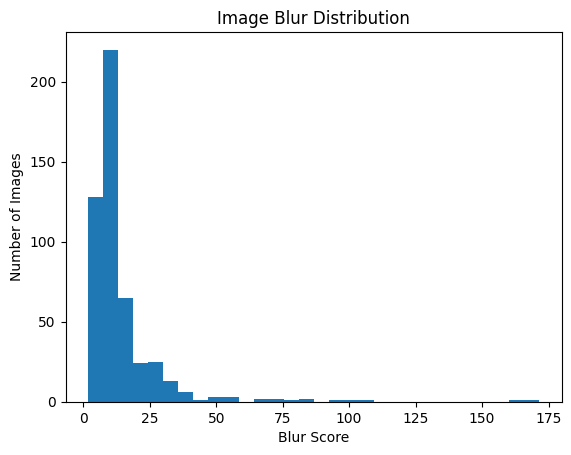

In [17]:
plt.hist(blur_scores, bins=30)
plt.xlabel("Blur Score")
plt.ylabel("Number of Images")
plt.title("Image Blur Distribution")
plt.show()

In [18]:
#check black borders
black_pixels = np.mean(gray < 10)

In [19]:
black_percentages = []

for img_name in df_train.image[:500]:

    img = cv2.imread(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{img_name}.jpeg")

    if img is None:
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    black_percentages.append(np.mean(gray < 10))

print(black_percentages[:10])

[np.float64(0.5290212069134101), np.float64(0.5296205691170969), np.float64(0.364865540695016), np.float64(0.36481116318650614), np.float64(0.5024466285093583), np.float64(0.5023464108654826), np.float64(0.2503955269140883), np.float64(0.2604101175506783), np.float64(0.5255927545343697), np.float64(0.5254378580183408)]


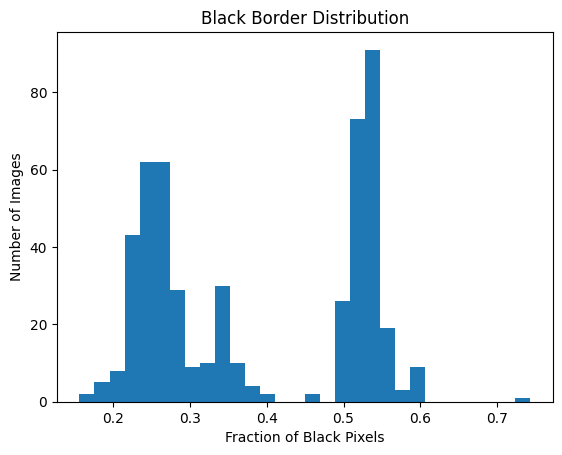

In [20]:
plt.hist(black_percentages, bins=30)
plt.xlabel("Fraction of Black Pixels")
plt.ylabel("Number of Images")
plt.title("Black Border Distribution")
plt.show()

In [21]:
# Test dataset
#----------------
#paths_test = glob('/kaggle/input/diabetic-retinopathy-test-unzipped/test/*.jpeg')
#image=cv2.imread(paths_test[0])
#plt.imshow(image)


In [22]:
#file_sub="/kaggle/input/diabetic-retinopathy-detection/sampleSubmission.csv.zip"
#df_submission=pd.read_csv(file_sub,sep=',')
#df_submission.loc[0, 'level']=1
#df_submission

In [23]:
#df_submission.to_csv('submission.csv', index=False)

In [24]:
#---------------------------------------------------------------------------------------------------------------------------------------------------
# preprocess edited images

# Preprocessed data

## Load preprocessed data

In [25]:
# Load csv and transform it
file_lbl="/kaggle/input/diabetic-retinopathy-detection/trainLabels.csv.zip"
df_train_edited_full = pd.read_csv(file_lbl,sep=',')
df_train_edited_full

df_train_edited_full["image"] = df_train_edited_full["image"]+"_edited"
df_train_edited_full


,image,level
0,10_left_edited,0
1,10_right_edited,0
2,13_left_edited,0
3,13_right_edited,0
4,15_left_edited,1
...,...,...
35121,44347_right_edited,0
35122,44348_left_edited,0
35123,44348_right_edited,0
35124,44349_left_edited,0


### CHANGE 2 (part 1) – Patient id
Image names look like `10_left` / `10_right`: the number before `_` is the patient.
We extract it so that both eyes of a patient can be kept together when splitting.

In [ ]:
# [ADDED] Patient id: "10_left_edited" -> "10". Both eyes of the same patient share the same id.
df_train_edited_full["patient_id"] = df_train_edited_full["image"].str.split("_").str[0]

print("Number of images  :", len(df_train_edited_full))
print("Number of patients:", df_train_edited_full["patient_id"].nunique())
# Most patients should have exactly 2 images (left + right eye)
print(df_train_edited_full.groupby("patient_id").size().value_counts())

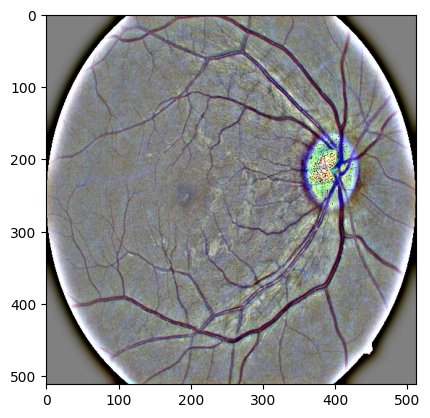

In [26]:
# Show first image
paths_train_edited = glob('/kaggle/input/datasets/jullopz/retinoplathy-detection-edited-v1/edited/*.jpeg')
image=cv2.imread(paths_train_edited[0])
plt.imshow(image)

## Apply transformation to preprocessed images

In [27]:
#Define transformations to be made to train dataset
train_transform = A.Compose([

    A.HorizontalFlip(p=0.5),

    A.VerticalFlip(p=0.5),

    A.Rotate(
        limit=180,
        p=0.7
    ),

    A.ShiftScaleRotate(
        shift_limit=0.05,
        scale_limit=0.10,
        rotate_limit=0,
        p=0.5
    ),

    A.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.15,
        hue=0.02,
        p=0.7
    ),

    A.OneOf([
        A.GaussianBlur(blur_limit=5),
        A.Sharpen()
    ], p=0.3),

    A.GaussNoise(std_range=(0.05, 0.15), p=0.2),
    
    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),

    ToTensorV2()
])

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [28]:
# Define Normalize image for validation dataset
valid_transform = A.Compose([

    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),

    ToTensorV2()

])

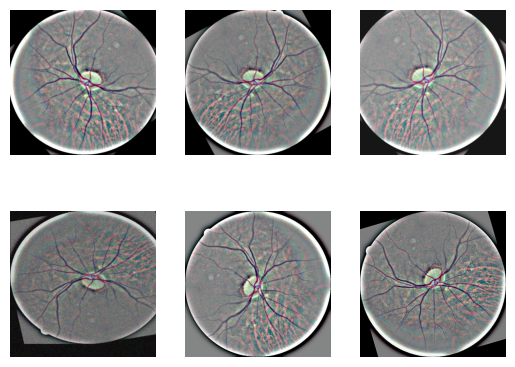

In [29]:
# Show transformed image (first image)
img = np.array(Image.open(f"/kaggle/input/datasets/jullopz/retinoplathy-detection-edited-v1/edited/{df_train_edited_full.iloc[0].image}.jpeg"))

for i in range(6):

    aug = train_transform(image=img)["image"]

    aug = aug.permute(1,2,0).numpy()

    aug = aug * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])

    plt.subplot(2,3,i+1)
    plt.imshow(np.clip(aug,0,1))
    plt.axis("off")

plt.show()

### CHANGE 3 (part 1) – Label as float
With MSE (regression) the target is the level itself as a real number, so the dataset returns a `float32` label.

In [ ]:
# Create functions to transform the images
class RetinaDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        img_path = os.path.join(self.image_dir, self.df.iloc[idx]["image"] + ".jpeg")
        img = np.array(Image.open(img_path).convert("RGB"))
        label = self.df.iloc[idx]["level"]

        if self.transform:
            img = self.transform(image=img)["image"]

        # [CHANGED] dtype torch.long -> torch.float32.
        # The model is now a regressor trained with MSE: the target is the level (0.0 ... 4.0).
        return img, torch.tensor(label, dtype=torch.float32)

### CHANGE 2 (part 2) – Train/validation split by patient
Before: `train_test_split` on **images** → the left eye of a patient could be in train and the right eye in validation.
Both eyes are strongly correlated (same person, same diabetes), so the model "already saw" part of the validation
patient and the validation score was too optimistic (leakage).

Now: `StratifiedGroupKFold` with `groups = patient_id` keeps **all images of a patient in the same group**,
while keeping the level distribution as similar as possible between train and validation (`y = level`).
With 5 folds, 1 fold (≈20%) is used for validation and the other 4 (≈80%) for training.

In [ ]:
# [CHANGED] Split train dataset into train and validation BY PATIENT
# (was: train_test_split(..., test_size=0.2, stratify=level), which split by image)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_idx, valid_idx = next(
    sgkf.split(
        df_train_edited_full,
        y=df_train_edited_full["level"],          # stratify on the level
        groups=df_train_edited_full["patient_id"]  # never split a patient
    )
)

train_df_08 = df_train_edited_full.iloc[train_idx].reset_index(drop=True)
valid_df_02 = df_train_edited_full.iloc[valid_idx].reset_index(drop=True)

# [ADDED] Sanity checks: no patient in both sets, and similar level distributions
assert set(train_df_08["patient_id"]).isdisjoint(set(valid_df_02["patient_id"])), "Patient leakage!"

print(f"Train: {len(train_df_08)} images | Valid: {len(valid_df_02)} images")
print(pd.DataFrame({
    "train %": train_df_08["level"].value_counts(normalize=True).sort_index() * 100,
    "valid %": valid_df_02["level"].value_counts(normalize=True).sort_index() * 100,
}).round(2))

## Model

In [32]:
########
# Model
########

In [33]:
# Define datasets to use
img_dir = "/kaggle/input/datasets/jullopz/retinoplathy-detection-edited-v1/edited"

train_dataset = RetinaDataset(
    train_df_08,
    image_dir = img_dir,
    transform=train_transform
)

valid_dataset = RetinaDataset(
    valid_df_02,
    image_dir = img_dir,
    transform=valid_transform
)
    

In [34]:
# Dataloaders
# Train data to load data to the model

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

# Validate data

valid_loader = DataLoader(
    valid_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

### CHANGE 1 – Model: EfficientNet-B0 → EfficientNetV2-S
EfficientNetV2-S (~21M parameters vs ~5M for B0) has a clearly better ImageNet accuracy (84.2% vs 77.7% top-1),
uses Fused-MBConv blocks that are faster to train on GPU and was trained with progressive resizing at
high resolution, which fits our 512×512 fundus images where lesions (microaneurysms, exudates) are very small.
It uses the same ImageNet normalisation as before, so the transforms do not change.

If it is too slow / out of memory on the T4: reduce `batch_size` to 8, or go back to a smaller model
(`efficientnet_b3`). If you have more GPU time: `efficientnet_v2_m`.

### CHANGE 3 (part 2) – 1 output instead of 5
The last layer now outputs **one number** (a continuous severity score) instead of 5 class logits.

In [ ]:
# [CHANGED] Define model to use: EfficientNetV2-S pretrained on ImageNet (was efficientnet_b0)
model = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.IMAGENET1K_V1)

# [CHANGED] 1 output (regression score) instead of 5 categories (classification).
# The classifier of EfficientNetV2 is also Sequential(Dropout, Linear), so index [1] is still the Linear layer.
NUM_OUTPUTS = 1
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_OUTPUTS)

In [36]:
# Use CUDA to process the model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

In [37]:
#print(device)

### CHANGE 3 (part 3) – Loss: CrossEntropy → MSE
Levels 0–4 are **ordered** (4 is worse than 3, which is worse than 2...).
CrossEntropy treats them as unrelated classes: predicting 4 for a healthy eye costs the same as predicting 1.
With MSE on the level, an error of 4 costs 16× more than an error of 1, which is exactly the spirit of the
competition metric (quadratic weighted kappa).

**[ADDED]** Mixed precision (AMP): EfficientNetV2-S is ~4× bigger than B0; AMP makes training ~2× faster
and uses less memory on the T4.

In [ ]:
# [CHANGED] Define loss function: Mean Squared Error (was CrossEntropyLoss)
criterion = nn.MSELoss()

# update weights
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

# Define epochs
epochs = 10

# [ADDED] Mixed precision (float16) on GPU to speed up the bigger model
USE_AMP = torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

### CHANGE 4 – Make the predicted distribution follow the train distribution
The model outputs a continuous score. Instead of rounding it (which tends to put almost everything in levels 0 and 2),
we **rank** all the images by score and cut the ranking so that the percentage of each predicted level equals the
percentage observed in train (e.g. if 2% of the train eyes are level 4, the 2% highest scores become level 4).
This is used both on validation (to choose the best epoch) and on the test predictions.

In [ ]:
# [ADDED] Helper functions to convert the continuous scores of the model into levels 0-4

NUM_LEVELS = 5

def scores_to_levels_by_rounding(scores):
    # Naive way: round the score and clip it to [0, 4]
    return np.clip(np.rint(scores), 0, NUM_LEVELS - 1).astype(int)


def scores_to_levels_by_distribution(scores, target_props):
    # CHANGE 4: assign the levels so that the predicted distribution equals target_props.
    # 1) sort the images from the lowest to the highest score
    # 2) the lowest X0% get level 0, the next X1% get level 1, ..., the highest X4% get level 4,
    #    where X0..X4 are the proportions of each level in the train set.
    # Example: if train has 2% of level 4, exactly 2% of the predictions will be level 4.
    scores = np.asarray(scores, dtype=float)
    n = len(scores)
    order = np.argsort(scores, kind="stable")                       # indices from lowest to highest score
    bounds = np.round(np.cumsum(target_props) * n).astype(int)      # cumulative number of images per level
    bounds[-1] = n                                                  # make sure every image gets a level
    levels = np.empty(n, dtype=int)
    start = 0
    for level, end in enumerate(bounds):
        levels[order[start:end]] = level
        start = end
    return levels


# [ADDED] Proportion of each level (0..4) in the train split, used for the validation
train_level_props = (
    train_df_08["level"].value_counts(normalize=True)
    .reindex(range(NUM_LEVELS), fill_value=0).values
)
print("Train level proportions:", np.round(train_level_props, 4))

# [ADDED] Proportion of each level in the FULL train set (35 126 images), used for the test predictions.
# Saved to a json file so that image_prediction.py reads it instead of hardcoding the numbers.
# Download it from the Kaggle output together with best_model.pth.
full_train_level_props = (
    df_train_edited_full["level"].value_counts(normalize=True)
    .reindex(range(NUM_LEVELS), fill_value=0).values
)
with open("train_level_props.json", "w") as f:
    json.dump({
        "levels": list(range(NUM_LEVELS)),
        "counts": df_train_edited_full["level"].value_counts().reindex(range(NUM_LEVELS), fill_value=0).tolist(),
        "proportions": full_train_level_props.tolist(),
    }, f, indent=2)
print("Full train level proportions (saved to train_level_props.json):", np.round(full_train_level_props, 4))

## Model run

### Training loop – changes
- **[CHANGED]** `outputs.squeeze(1)`: the model returns shape `(batch, 1)`, MSE needs `(batch,)` like the labels.
- **[ADDED]** Mixed precision (`torch.autocast` + `GradScaler`).
- **[ADDED]** Validation quadratic weighted kappa (QWK), with rounding and with distribution matching (CHANGE 4).
- **[CHANGED]** The best model is saved on the **best validation QWK** (competition metric) instead of the lowest
  validation loss.

In [ ]:
# [CHANGED] To calculate best model (best weights): now based on validation kappa (was validation loss)
best_valid_kappa = -1.0

# Model run
for epoch in range(epochs):

# Training
    model.train()
    train_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        # [ADDED] mixed precision forward pass
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            # [CHANGED] squeeze(1): (batch, 1) -> (batch,) to match labels for MSE
            outputs = model(images).squeeze(1)

        # loss computed in float32 for numerical stability
        loss = criterion(outputs.float(), labels)

        # [CHANGED] backward/step through the GradScaler (was loss.backward(); optimizer.step())
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

    train_loss = train_loss / len(train_loader)

# Validate
    model.eval()
    valid_loss = 0
    valid_scores = []   # [ADDED] keep the predicted scores to compute the kappa
    valid_labels = []   # [ADDED]

    with torch.no_grad():

        for images, labels in valid_loader:

            images = images.to(device)
            labels = labels.to(device)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                outputs = model(images).squeeze(1)   # [CHANGED] squeeze(1)

            loss = criterion(outputs.float(), labels)

            valid_loss += loss.item()
            valid_scores.extend(outputs.float().cpu().numpy())   # [ADDED]
            valid_labels.extend(labels.cpu().numpy().astype(int)) # [ADDED]

    valid_loss = valid_loss / len(valid_loader)

    # [ADDED] Quadratic weighted kappa on validation
    kappa_round = cohen_kappa_score(
        valid_labels, scores_to_levels_by_rounding(valid_scores), weights="quadratic")
    kappa_dist = cohen_kappa_score(
        valid_labels, scores_to_levels_by_distribution(valid_scores, train_level_props), weights="quadratic")

    print(f"Epoch {epoch+1}: Train Loss = {train_loss:.4f} | Valid Loss = {valid_loss:.4f} | "
          f"Valid QWK (rounding) = {kappa_round:.4f} | Valid QWK (train distribution) = {kappa_dist:.4f}")

    # [CHANGED] save on best kappa with distribution matching (the method used for the submission)
    if kappa_dist > best_valid_kappa:

        best_valid_kappa = kappa_dist

        torch.save(
            model.state_dict(),
            "best_model.pth")

        print(f"New best model saved! Validation QWK = {kappa_dist:.4f}")

# Test images

In [ ]:
#Load the model if needed and process test images
# [CHANGED] Define model to use: EfficientNetV2-S (must be the same architecture as in training)
model_test = efficientnet_v2_s(weights=None)

# [CHANGED] 1 output (regression) instead of 5 categories
model_test.classifier[1] = nn.Linear(model_test.classifier[1].in_features, NUM_OUTPUTS)

#Load the weights
model_test.load_state_dict(torch.load("best_model.pth", map_location=device))

model_test.to(device)

model_test.eval()

In [41]:
valid_transform_test = A.Compose([

    A.Resize(512, 512),

    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),

    ToTensorV2()
])

In [42]:
# Dataset of test images
class TestDataset(Dataset):

    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        img_path = self.image_paths[idx]

        image = np.array(Image.open(img_path).convert("RGB"))

        if self.transform:
            image = self.transform(image=image)["image"]

        image_name = os.path.basename(img_path).replace(".jpeg", "")

        return image, image_name






In [43]:
#Load images
img_dir_test = "/kaggle/input/diabetic-retinopathy-test-unzipped/test"

test_paths = sorted(
    glob(os.path.join(img_dir_test, "*.jpeg"))
)
print(len(test_paths))
print(test_paths[:3])



53576
['/kaggle/input/diabetic-retinopathy-test-unzipped/test/10000_left.jpeg', '/kaggle/input/diabetic-retinopathy-test-unzipped/test/10000_right.jpeg', '/kaggle/input/diabetic-retinopathy-test-unzipped/test/10001_left.jpeg']


In [44]:
# Image directory
#img_dir_test = "/kaggle/input/datasets/jullopz/Diabetic Retinopathy test unzipped/test"

test_dataset = TestDataset(
    image_paths = test_paths,
    transform=valid_transform_test
)

# Data loader
test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

## Generate predictions

### Prediction – changes
(Optional in this notebook: the official predictions are made with `image_prediction.py`.)
- **[CHANGED]** `model.eval()` → `model_test.eval()` (the model used for prediction is `model_test`).
- **[CHANGED]** No more `argmax`: we keep the continuous score of every test image, and then
- **[ADDED]** CHANGE 4: the scores are converted to levels so that the predicted distribution equals the
  distribution of the **whole** train set (all 35 126 labelled images).

In [ ]:
# Predict test images
test_scores = []   # [CHANGED] store continuous scores (was: predictions with argmax)
test_names = []

model_test.eval()   # [CHANGED] was model.eval()

with torch.no_grad():

    for images, image_names in test_loader:

        images = images.to(device)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            outputs = model_test(images).squeeze(1)   # [CHANGED] (batch, 1) -> (batch,)

        test_scores.extend(outputs.float().cpu().numpy())
        test_names.extend(image_names)

# [ADDED] CHANGE 4: predicted distribution = distribution of the full train set
# (full_train_level_props is computed in the helper functions cell)
test_levels = scores_to_levels_by_distribution(test_scores, full_train_level_props)

predictions = [[name, int(level)] for name, level in zip(test_names, test_levels)]

# [ADDED] Check: predicted distribution vs train distribution
print(pd.DataFrame({
    "train %": full_train_level_props * 100,
    "predicted %": pd.Series(test_levels).value_counts(normalize=True)
                     .reindex(range(NUM_LEVELS), fill_value=0).values * 100,
}).round(2))

In [46]:
# Export results in csv
submission = pd.DataFrame(
    predictions,
    columns=["image", "level"]
)

submission.to_csv(
    "submission.csv",
    index=False
)